<a href="https://colab.research.google.com/github/alsedawy/AI/blob/main/copy_of_tinynet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

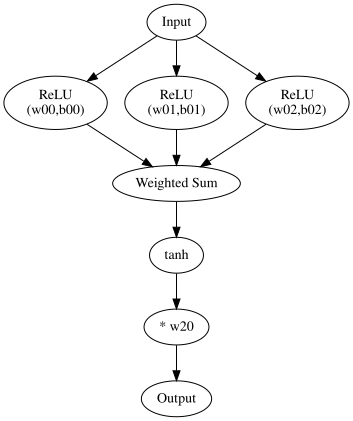

Zero Init Epoch: 0 Loss: 0.5927756428718567
Zero Init Epoch: 200 Loss: 0.5927756428718567
Zero Init Epoch: 400 Loss: 0.5927756428718567
Zero Init Epoch: 600 Loss: 0.5927756428718567
Zero Init Epoch: 800 Loss: 0.5927756428718567


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


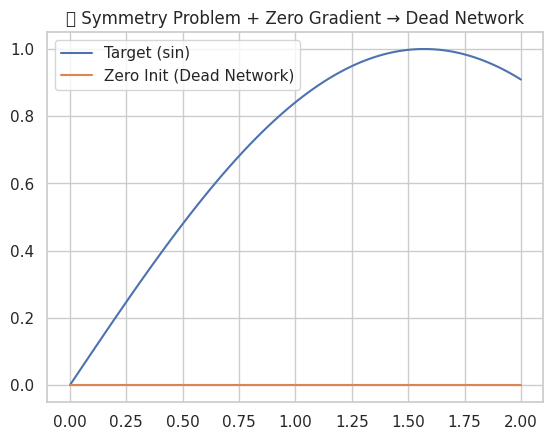

Random Init Epoch: 0 Loss: 0.5952204465866089
Random Init Epoch: 400 Loss: 0.0010033197468146682
Random Init Epoch: 800 Loss: 0.0008605330367572606
Random Init Epoch: 1200 Loss: 0.0008486766600981355
Random Init Epoch: 1600 Loss: 0.0008427607244811952


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


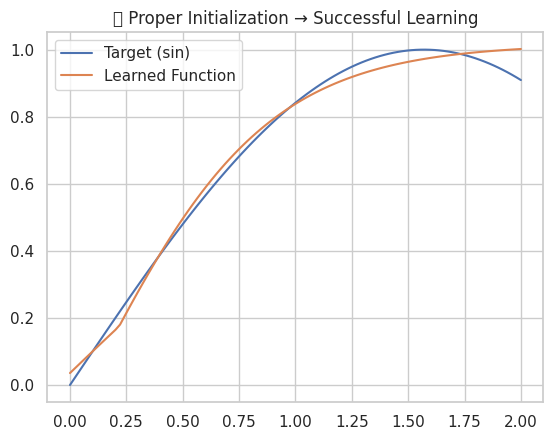

In [ ]:
# ==============================
# 1️⃣ رسم الشبكة
# ==============================

from graphviz import Digraph

dot = Digraph()

dot.node('x','Input')

dot.node('l1','ReLU\n(w00,b00)')
dot.node('l2','ReLU\n(w01,b01)')
dot.node('l3','ReLU\n(w02,b02)')

dot.edge('x','l1')
dot.edge('x','l2')
dot.edge('x','l3')

dot.node('sum','Weighted Sum')
dot.edge('l1','sum')
dot.edge('l2','sum')
dot.edge('l3','sum')

dot.node('tanh','tanh')
dot.edge('sum','tanh')

dot.node('w20','* w20')
dot.edge('tanh','w20')

dot.node('out','Output')
dot.edge('w20','out')

display(dot)


# ==============================
# 2️⃣ المكتبات
# ==============================

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt


# ==============================
# 3️⃣ النموذج (نسختين)
# ==============================

# ❌ Zero Initialization (المشكلة)
class TinyNetZero(nn.Module):
    def __init__(self):
        super().__init__()

        self.w00 = nn.Parameter(torch.tensor(0.0))
        self.b00 = nn.Parameter(torch.tensor(0.0))

        self.w01 = nn.Parameter(torch.tensor(0.0))
        self.b01 = nn.Parameter(torch.tensor(0.0))

        self.w02 = nn.Parameter(torch.tensor(0.0))
        self.b02 = nn.Parameter(torch.tensor(0.0))

        self.w11 = nn.Parameter(torch.tensor(0.0))
        self.w12 = nn.Parameter(torch.tensor(0.0))
        self.w13 = nn.Parameter(torch.tensor(0.0))

        self.w20 = nn.Parameter(torch.tensor(0.0))

    def forward(self,x):
        l1 = torch.relu(x*self.w00 + self.b00)
        l2 = torch.relu(x*self.w01 + self.b01)
        l3 = torch.relu(x*self.w02 + self.b02)

        s = l1*self.w11 + l2*self.w12 + l3*self.w13

        y = torch.tanh(s)*self.w20
        return y


# ✅ Random Initialization (الحل)
class TinyNetRandom(nn.Module):
    def __init__(self):
        super().__init__()

        def r():
            return nn.Parameter(torch.randn(1)*0.1)

        self.w00 = r(); self.b00 = r()
        self.w01 = r(); self.b01 = r()
        self.w02 = r(); self.b02 = r()

        self.w11 = r(); self.w12 = r(); self.w13 = r()
        self.w20 = r()

    def forward(self,x):
        l1 = torch.relu(x*self.w00 + self.b00)
        l2 = torch.relu(x*self.w01 + self.b01)
        l3 = torch.relu(x*self.w02 + self.b02)

        s = l1*self.w11 + l2*self.w12 + l3*self.w13

        y = torch.tanh(s)*self.w20
        return y


# ==============================
# 4️⃣ البيانات
# ==============================

x = torch.linspace(0,2,100)
y_true = torch.sin(x)


# ==============================
# 5️⃣ تجربة 1: Symmetry Problem
# ==============================

model_zero = TinyNetZero()

optimizer = optim.SGD(model_zero.parameters(), lr=0.05)
loss_fn = nn.MSELoss()

for epoch in range(1000):
    y_pred = model_zero(x)
    loss = loss_fn(y_pred, y_true)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print("Zero Init Epoch:", epoch, "Loss:", loss.item())


with torch.no_grad():
    y_zero = model_zero(x)

plt.figure()
plt.plot(x.numpy(), y_true.numpy(), label="Target (sin)")
plt.plot(x.numpy(), y_zero.numpy(), label="Zero Init (Dead Network)")
plt.title("❌ Symmetry Problem + Zero Gradient → Dead Network")
plt.legend()
plt.show()


# ==============================
# 6️⃣ تجربة 2: التعلم الصحيح
# ==============================

model_good = TinyNetRandom()

optimizer = optim.Adam(model_good.parameters(), lr=0.01)

for epoch in range(2000):
    y_pred = model_good(x)
    loss = loss_fn(y_pred, y_true)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 400 == 0:
        print("Random Init Epoch:", epoch, "Loss:", loss.item())


with torch.no_grad():
    y_good = model_good(x)

plt.figure()
plt.plot(x.numpy(), y_true.numpy(), label="Target (sin)")
plt.plot(x.numpy(), y_good.numpy(), label="Learned Function")
plt.title("✅ Proper Initialization → Successful Learning")
plt.legend()
plt.show()